In [2]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt


In [3]:
def bs_call(S0, K, T, r, sigma):
    """European call option s Black-Scholes therotical price."""
    d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return S0 * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

In [4]:
def mc_call(S0, K, T, r, sigma, n_paths=100_000, seed=42):
    """用蒙特卡洛模拟给欧式看涨期权定价"""
    rng = np.random.default_rng(seed)
    Z = rng.standard_normal(n_paths)                                     # 标准正态随机数
    ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)  # 到期时的股价
    payoff = np.maximum(ST - K, 0)                                       # 看涨期权到期收益
    discounted = np.exp(-r * T) * payoff                                 # 折现回今天
    price = discounted.mean()
    stderr = discounted.std(ddof=1) / np.sqrt(n_paths)                   # 标准误差
    return price, stderr

In [5]:
S0, K, T, r, sigma = 100, 100, 1.0, 0.05, 0.2

bs = bs_call(S0, K, T, r, sigma)
mc, se = mc_call(S0, K, T, r, sigma)

print(f"Black-Scholes:  {bs:.4f}")
print(f"Monte Carlo:    {mc:.4f} ± {1.96*se:.4f} (95% CI)")
print(f"Difference:     {mc - bs:.4f}")

Black-Scholes:  10.4506
Monte Carlo:    10.4205 ± 0.0917 (95% CI)
Difference:     -0.0300


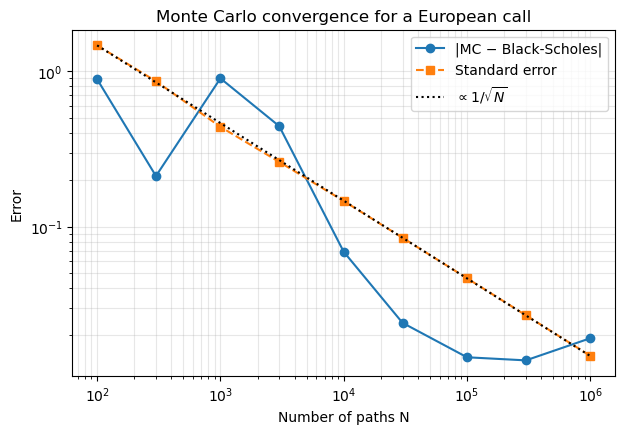

In [6]:
n_list = [100, 300, 1_000, 3_000, 10_000, 30_000, 100_000, 300_000, 1_000_000]
errors, stderrs = [], []

for n in n_list:
    mc, se = mc_call(S0, K, T, r, sigma, n_paths=n, seed=0)
    errors.append(abs(mc - bs))
    stderrs.append(se)

plt.figure(figsize=(7, 4.5))
plt.loglog(n_list, errors, "o-", label="|MC − Black-Scholes|")
plt.loglog(n_list, stderrs, "s--", label="Standard error")
plt.loglog(n_list, stderrs[0] * np.sqrt(n_list[0] / np.array(n_list)), "k:", label=r"$\propto 1/\sqrt{N}$")
plt.xlabel("Number of paths N")
plt.ylabel("Error")
plt.title("Monte Carlo convergence for a European call")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.savefig("convergence.png", dpi=150, bbox_inches="tight")
plt.show()